# DINOv2 ViT-S/14, fine-tuned: 50-epoch multi-task run (local)

Same fine-tuned model, data, augmentation and settings as `train_local_dinov2_finetuned.ipynb`, with **one change:
50 epochs instead of 30**. Only the multi-task model is trained. The 30-epoch run stays where it is, so the two can
be compared. For the frozen-backbone version, see `train_local_dinov2_frozen.ipynb`.

| | 30-epoch run (existing) | This notebook |
|---|---|---|
| Epochs | 30 | **50** |
| Everything else | `config.yaml` | `config.yaml` (unchanged) |
| Output folder | `outputs/multitask_dinov2` | `outputs/multitask_dinov2_50ep` |

**Why:** validation disease accuracy was still rising until about epoch 24 and only flattened because the cosine
learning rate had decayed to almost 0. With 50 epochs the schedule is stretched, so the backbone keeps a useful
learning rate for longer. Early stopping (patience 8) still applies.

**Time:** about 1.7x the 30-epoch run.

After training, section 6 runs the **logit-adjusted calibration** (`baseline/MultiTaskBaseline/calibrate.py`) on
both runs. It's the same post-hoc method, grid and cross-fit as the EfficientNet-B0 v2 notebook, so the numbers are
comparable across backbones. It only changes how the saved test logits are scored; no weights change.

## How to judge the result

Compare the two runs in section 7 on **unseen disease top-1, unseen pair top-1, HM and AUC**, not on
`val_score`. The validation split is a random 10% of the training images, so it only contains seen pairs and is
much easier than the test sets (30-epoch run: disease 0.905 on validation vs 0.734 on seen test).

Calibrated HM, from least to most optimistic:

| Column | What it is | Use it for |
|---|---|---|
| `HM logit-adj (held-out)` | Settings tuned on one half of the test images, scored on the other half | **The calibrated number to report** |
| `HM bias-only (oracle)` | One unseen-pair bias, chosen on all test images | The standard CZSL reference, together with AUC |
| `HM logit-adj (all test)` | All settings tuned on all test images | Reference only; optimistic |

There's no validation set with unseen pairs, so the held-out estimate still uses test images (in held-out halves).
Say so in the report.

## Before the first run

1. **GPU:** an NVIDIA GPU with at least 4 GB of memory and PyTorch with CUDA. By default the GPU gets 32 images at
   a time and gradients are added up over 2 steps (`MICRO_BATCH`), so the model still updates once per 64 images.
2. **Packages:** `pip install timm pyyaml pandas matplotlib scikit-learn tqdm`
3. **Dataset:** `dataset/DPD_Small_train.csv`, `dataset/DPD_Small_test_seen.csv`, `dataset/DPD_Small_test_unseen.csv`
   and `dataset/DPD_Small_dataset/*.jpg`.

Close other programs that use the GPU, keep a laptop plugged in, and turn off sleep while training.

## If training stops

Run all cells again. A finished run is skipped. A run that was cut off restarts from epoch 1, because `train.py`
can't resume yet.

## 1. Settings

In [1]:
# ===== Edit these =====
FORCE_RETRAIN = False   # True = train again even if the 50-epoch run is already finished
MICRO_BATCH   = 32      # images per GPU step; gradients add up to the config's batch (64). Lower to 16 if out of memory.
                        # None = use config.yaml's batch unchanged (64 in one go).
SHARE_DIR     = None    # optional: a synced team folder, e.g. "G:/My Drive/AML_Group_Project/aml_runs".
                        # None = make a zip to upload by hand instead (last cell).
CALIBRATE_BASELINE = True   # also re-evaluate the 30-epoch checkpoint (about a minute) so it gets logit-adjusted
                            # numbers too. Needs outputs/multitask_dinov2/best.pt. Its results go to a separate
                            # eval_recal/ folder; the existing eval/ folder isn't touched.
# ======================

EPOCHS = 50                             # the only change from config.yaml (30)
MODEL_DIR = "baseline/MultiTaskBaseline/DINOv2"
CONFIG    = "baseline/MultiTaskBaseline/DINOv2/config.yaml"
CALIBRATE = "baseline/MultiTaskBaseline/calibrate.py"   # shared by B0, B3 and DINOv2
RUN       = "multitask_dinov2_50ep"     # new output folder
BASELINE  = "multitask_dinov2"          # existing 30-epoch run, for comparison
RUN_EVAL      = f"outputs/{RUN}/eval"
BASELINE_EVAL = f"outputs/{BASELINE}/eval_recal"

## 2. Check the repo, GPU and dataset

The scripts use paths relative to the repo root, so this cell moves there first. The GPU and library versions are
printed so the report can say where the model was trained. The GPU is checked from a separate process, so this
notebook never holds GPU memory that training needs.

In [2]:
import os
import platform
import subprocess
import sys

# Jupyter starts in this notebook's folder. Walk up to the repo root.
here = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(here, MODEL_DIR)):
    parent = os.path.dirname(here)
    if parent == here:
        raise FileNotFoundError(f"Can't find {MODEL_DIR}. Open this notebook from inside the project repo.")
    here = parent
os.chdir(here)
print("Repo root:", here)

r = subprocess.run(["git", "log", "-1", "--format=%h %s (%cr)"], capture_output=True, text=True)
print("Code version:", r.stdout.strip() or "unknown (git not found)")

PROBE = r"""
import torch
ok = torch.cuda.is_available()
free, total = torch.cuda.mem_get_info() if ok else (0, 0)
print(ok, torch.cuda.get_device_name(0) if ok else "-", free >> 20, total >> 20, torch.__version__, torch.version.cuda, sep="|")
"""
probe = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
assert probe.returncode == 0, f"Can't import torch in {sys.executable}:\n{probe.stderr}"
ok, GPU_NAME, free_mb, total_mb, torch_ver, cuda_ver = probe.stdout.strip().splitlines()[-1].split("|")
print(f"Python {platform.python_version()} ({sys.executable})")
print(f"torch {torch_ver} | CUDA {cuda_ver} | {platform.system()}")
assert ok == "True", ("No CUDA GPU found. This kernel has a CPU-only PyTorch: pick a kernel with CUDA PyTorch "
                      "(Select Kernel, top right) or install it, then run this cell again.")
free_gb, total_gb = int(free_mb) / 1024, int(total_mb) / 1024
print(f"GPU: {GPU_NAME} ({total_gb:.1f} GB, {free_gb:.1f} GB free)")
if free_gb < 4:
    print("Warning: under 4 GB free. Close programs that use the GPU (browser, games, video, other notebooks), "
          "or lower MICRO_BATCH to 16.")

import timm
print("timm", timm.__version__)

import pandas as pd

CSVS = ["DPD_Small_train.csv", "DPD_Small_test_seen.csv", "DPD_Small_test_unseen.csv"]
IMG_DIR = "dataset/DPD_Small_dataset"
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
missing = [n for n in CSVS if not os.path.isfile(f"dataset/{n}")]
assert not missing, f"Missing from dataset/: {missing}"
assert os.path.isdir(IMG_DIR), f"{IMG_DIR} not found. Unpack DPD_Small.7z there."

# Every image named in the CSVs must exist (first column; a header row, if any, is skipped).
names = pd.concat([pd.read_csv(f"dataset/{n}", header=None, usecols=[0])[0] for n in CSVS]).astype(str)
names = names[names.str.lower().str.endswith(IMG_EXT)]
have = set(os.listdir(IMG_DIR))
missing = [n for n in names if os.path.basename(n) not in have]
assert not missing, f"{len(missing)} images in the CSVs are missing, e.g. {missing[:3]}"
print(f"Images: {len(have)} (all {len(names)} CSV entries found)")

Repo root: c:\COS30082_ML_Project
Code version: 772ac96 docs: add backbone comparison notes (5 hours ago)
Python 3.14.2 (c:\Users\USER\AppData\Local\Programs\Python\Python314\python.exe)
torch 2.14.1+cu126 | CUDA 12.6 | Windows
GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.0 GB, 5.0 GB free)


c:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


timm 1.0.31
Images: 11448 (all 11448 CSV entries found)


## 3. Helpers

`train()` and `evaluate()` run the scripts as separate processes, with live output here. That also avoids a
Windows problem where data-loader workers crash when training code runs inside Jupyter itself.

In [3]:
import codecs
import csv

import yaml

os.makedirs("outputs", exist_ok=True)
with open(CONFIG) as f:
    CFG = yaml.safe_load(f)
PATIENCE = CFG["train"].get("patience", 0)

# config.yaml with 50 epochs and (optionally) smaller GPU steps. The run's saved config.yaml records all of this.
local = yaml.safe_load(open(CONFIG))
local["experiment"] = RUN
local["train"]["epochs"] = EPOCHS
effective = CFG["train"]["batch_size"] * CFG["train"].get("accum_steps", 1)
if MICRO_BATCH and MICRO_BATCH != CFG["train"]["batch_size"]:
    assert effective % MICRO_BATCH == 0, f"MICRO_BATCH must divide the effective batch ({effective})"
    local["train"]["batch_size"] = MICRO_BATCH
    local["train"]["accum_steps"] = effective // MICRO_BATCH
TRAIN_CONFIG = "outputs/local_config_dinov2_50ep.yaml"
with open(TRAIN_CONFIG, "w") as f:
    yaml.safe_dump(local, f, sort_keys=False)
tc = local["train"]
print(f"Epochs: {tc['epochs']} | batch: {tc['batch_size']} x accum {tc.get('accum_steps', 1)} = {effective} "
      f"per update ({TRAIN_CONFIG})\n")


def run_status(exp, epochs=EPOCHS):
    """'done', 'partial' or 'missing' for a training run saved in outputs/."""
    hist = f"outputs/{exp}/history.csv"
    if not (os.path.isfile(hist) and os.path.isfile(f"outputs/{exp}/best.pt")):
        return "missing"
    with open(hist) as f:
        scores = [float(r["val_score"]) for r in csv.DictReader(f)]
    if not scores:
        return "partial"
    best_epoch = scores.index(max(scores)) + 1          # same rule as train.py
    early_stop = PATIENCE and len(scores) - best_epoch >= PATIENCE
    return "done" if len(scores) >= epochs or early_stop else "partial"


def run(args):
    """Run a script with this notebook's Python and stream its output. Stop in Jupyter stops it too."""
    print("$", " ".join(args), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8",
           "TQDM_MININTERVAL": "30"}   # fewer progress-bar updates keep the saved notebook small
    p = subprocess.Popen([sys.executable, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env)
    decoder = codecs.getincrementaldecoder("utf-8")(errors="replace")
    try:
        while chunk := p.stdout.read1(4096):
            sys.stdout.write(decoder.decode(chunk))
            sys.stdout.flush()
    except KeyboardInterrupt:
        if os.name == "nt":   # also stop the data-loader worker processes
            subprocess.run(["taskkill", "/F", "/T", "/PID", str(p.pid)], capture_output=True)
        else:
            p.terminate()
        p.wait()
        raise
    if p.wait():
        raise RuntimeError("Command failed, see the error above.")


def train():
    status = run_status(RUN)
    if status == "done" and not FORCE_RETRAIN:
        print(f"{RUN}: already finished, skipping. Set FORCE_RETRAIN = True to train it again.")
        return
    if status == "partial":
        print(f"{RUN}: found an unfinished run. Training restarts from epoch 1.")
    run([f"{MODEL_DIR}/train.py", "--config", TRAIN_CONFIG, "--mode", "multitask", "--experiment", RUN])


def evaluate(exp, out_dir, epochs=EPOCHS):
    if run_status(exp, epochs) != "done":
        print(f"Skipping evaluation of {exp}: training isn't finished (or best.pt is missing).")
        return
    ckpt = f"outputs/{exp}/best.pt"
    done = [f"{out_dir}/metrics.json", f"{out_dir}/logits.npz"]   # logits.npz is needed for calibration
    if (all(os.path.isfile(f) for f in done) and not FORCE_RETRAIN
            and min(os.path.getmtime(f) for f in done) > os.path.getmtime(ckpt)):
        print(f"{out_dir}: already evaluated, skipping.")
        return
    run([f"{MODEL_DIR}/evaluate.py", "--checkpoints", ckpt, "--out", out_dir,
         "--batch_size", "64"])   # smaller than the default 128 to fit the GPU; doesn't change the metrics


def calibrate(out_dir):
    logits, result = f"{out_dir}/logits.npz", f"{out_dir}/calibration_v2.json"
    if not os.path.isfile(logits):
        print(f"Skipping calibration of {out_dir}: no logits.npz (evaluate first).")
        return
    if (os.path.isfile(result) and not FORCE_RETRAIN
            and os.path.getmtime(result) > os.path.getmtime(logits)):
        print(f"{out_dir}: already calibrated, skipping.")
        return
    run([CALIBRATE, "--eval_dirs", out_dir])


print(f"{RUN:28s} {run_status(RUN)}")
print(f"{BASELINE:28s} {run_status(BASELINE, epochs=CFG['train']['epochs'])}  (30-epoch run, for comparison)")

Epochs: 50 | batch: 32 x accum 2 = 64 per update (outputs/local_config_dinov2_50ep.yaml)

multitask_dinov2_50ep        missing
multitask_dinov2             done  (30-epoch run, for comparison)


## 4. Train the multi-task model (50 epochs)

In [4]:
train()

$ baseline/MultiTaskBaseline/DINOv2/train.py --config outputs/local_config_dinov2_50ep.yaml --mode multitask --experiment multitask_dinov2_50ep
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
[data] train=7329 val=671
[model] vit_small_patch14_dinov2.lvd142m heads={'crop': 55, 'disease': 175} params=21.7M trainable=21.72M
[train] batch 32 x accum 2 = effective batch 64
train:   0%|          | 0/229 [00:00<?, ?it/s]c:\COS30082_ML_Project\baseline\MultiTaskBaseline\DINOv2\train.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more d

## 5. Evaluate on test_seen and test_unseen

Also saves the raw test logits (`logits.npz`) for calibration. With `CALIBRATE_BASELINE`, the 30-epoch checkpoint
is evaluated again into `outputs/multitask_dinov2/eval_recal`, because its first evaluation didn't save logits.

In [5]:
evaluate(RUN, RUN_EVAL)
if CALIBRATE_BASELINE:
    evaluate(BASELINE, BASELINE_EVAL, epochs=CFG["train"]["epochs"])

$ baseline/MultiTaskBaseline/DINOv2/evaluate.py --checkpoints outputs/multitask_dinov2_50ep/best.pt --out outputs/multitask_dinov2_50ep/eval --batch_size 64
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
                                              
                       Top-1    Top-5
  seen crop                      0.9230   0.9710
  seen disease                   0.7255   0.9240
  seen composition               0.7100   0.9160
  seen composition_closed_world  0.7100   0.9165
unseen crop                      0.7369   0.8798
unseen disease                   0.1057   0.2645
unseen composition               0.0601   0.3239
unseen composition_closed_world  0.7928   0.9814
harmonic mean (composition)      0.1108   0.4786
calibrated best HM, oracle bias picked on test 0.6482 (seen 0.5915

## 6. Logit-adjusted calibration (no retraining)

**The problem.** The model is heavily biased toward seen pairs: it never saw an unseen pair during training, so
those pairs always score lower. In the 30-epoch run, unseen pair top-1 is only 0.046 out of all 333 pairs, yet
0.809 when it only has to choose among the 10 unseen pairs. The model has the information, but the seen pairs win
the ranking.

**The fix.** Re-score the saved test logits. Each crop-disease pair $(c, d)$ gets

$$\text{score}(c,d\mid x) = \log\operatorname{softmax}\!\Big(\tfrac{\ell^{crop}}{T_c} - \tau_c\log\pi^{crop}\Big)_c
+ \log\operatorname{softmax}\!\Big(\tfrac{\ell^{dis}}{T_d} - \tau_d\log\pi^{dis}\Big)_d
- \tau_{pair}\log\pi_{(c,d)}\,[\text{seen}] + b\,[\text{unseen}]$$

| Setting | What it does |
|---|---|
| $T_c, T_d$ (temperature) | Values above 1 soften an overconfident head, so its second and third choices still count |
| $\tau_c, \tau_d$ (logit adjustment) | Subtract the class's training frequency $\pi$, so rare classes aren't drowned out by common ones |
| $\tau_{pair}$ | Penalises seen pairs that were frequent in training |
| $b$ (bias) | Added to every unseen pair, to undo the bias toward seen pairs |

All 1,008 combinations are searched, each with its best $b$. Model weights don't change. It runs on the CPU in
about a minute.

**Why the held-out number.** There's no validation set with unseen pairs, so the settings have to be chosen on
test images. To keep that honest, `calibrate.py` tunes on one half of the test images and scores on the other
half (both ways, 2 seeds), and reports the average: `HM logit-adj (held-out)`. That is the calibrated number to
report. `HM logit-adj (all test)` is tuned and scored on the same images, so it's only a reference.

**What it found (30-epoch run).** $T_d = 1.5$ and every $\tau = 0$, the same choice as for EfficientNet-B0.
Softening the disease head helps; subtracting the class frequency doesn't, probably because the test sets follow
the same long-tailed class balance as training. Held-out HM rose from 0.662 (bias only) to 0.700.

**What it can't do.** Calibration only re-weights scores the model already produces. It can't fix the disease
head itself: on unseen images it mostly predicts the disease it saw with that crop (unseen disease top-1 0.085).
For the 30-epoch run, the closed-world accuracies (seen 0.719, unseen 0.809) put the ceiling at roughly 0.76 HM.

Same method, grid and cross-fit seeds as the EfficientNet-B0 v2 notebook
(`baseline/SingleTaskBaseline/FineTunedB0(Logit+HyperparameterSearch)/`), which has the full derivation.
Outputs: `calibration_v2.json`, `cross_fit_v2.csv` and `calibration_search_v2.csv`, next to `metrics.json`.

In [6]:
calibrate(RUN_EVAL)
if CALIBRATE_BASELINE:
    calibrate(BASELINE_EVAL)

$ baseline/MultiTaskBaseline/calibrate.py --eval_dirs outputs/multitask_dinov2_50ep/eval
[calibrate] outputs/multitask_dinov2_50ep/eval
  fold 1/4: held-out HM top-1 0.6721
  fold 2/4: held-out HM top-1 0.6925
  fold 3/4: held-out HM top-1 0.6762
  fold 4/4: held-out HM top-1 0.6924
                              seen-1   unseen-1   HM-1     HM-5
  uncalibrated                0.7105   0.0601    0.1108   0.4786
  bias only (all test)        0.5910   0.7196    0.6490   0.9060
  logit-adj, held-out         0.6286   0.7487    0.6833   0.9200   <- report this
  logit-adj, all test         0.6175   0.7624    0.6824   0.9208
  all-test config: {'tau_c': 0.0, 'tau_d': 0.0, 'T_c': 0.7, 'T_d': 1.0, 'tau_pair': 0.0, 'bias': 7.20006608564985}

outputs/multitask_dinov2/eval_recal: already calibrated, skipping.


## 7. Results: 30 vs 50 epochs

The `change` row is 50 epochs minus 30 epochs. Look at the unseen columns, `HM`, `HM logit-adj (held-out)` and AUC first.
Compare the two runs' uncalibrated columns to see what the extra epochs did, and the calibrated columns to see what calibration adds on top.

Top-1 accuracy on the test sets (50-epoch run trained locally on NVIDIA GeForce RTX 3060 Laptop GPU)


,seen crop,seen disease,seen pair,unseen crop,unseen disease,unseen pair,unseen pair (closed),HM,best HM (oracle bias),AUC,HM logit-adj (held-out),HM-5 logit-adj (held-out),HM logit-adj (all test)
30 epochs,0.919,0.7335,0.7185,0.7507,0.0849,0.0456,0.8094,0.0857,0.6623,0.5453,0.6995,0.9172,0.7008
50 epochs,0.923,0.7255,0.7100,0.7369,0.1057,0.0601,0.7928,0.1108,0.6482,0.5282,0.6833,0.9200,0.6824
change,0.004,-0.0080,-0.0085,-0.0138,0.0207,0.0145,-0.0166,0.0251,-0.0141,-0.0171,-0.0162,0.0028,-0.0185


30 epochs: logit-adjusted config chosen on all test images: {'tau_c': 0.0, 'tau_d': 0.0, 'T_c': 1.0, 'T_d': 1.5, 'tau_pair': 0.0, 'bias': 4.761990064223342}
50 epochs: logit-adjusted config chosen on all test images: {'tau_c': 0.0, 'tau_d': 0.0, 'T_c': 0.7, 'T_d': 1.0, 'tau_pair': 0.0, 'bias': 7.20006608564985}


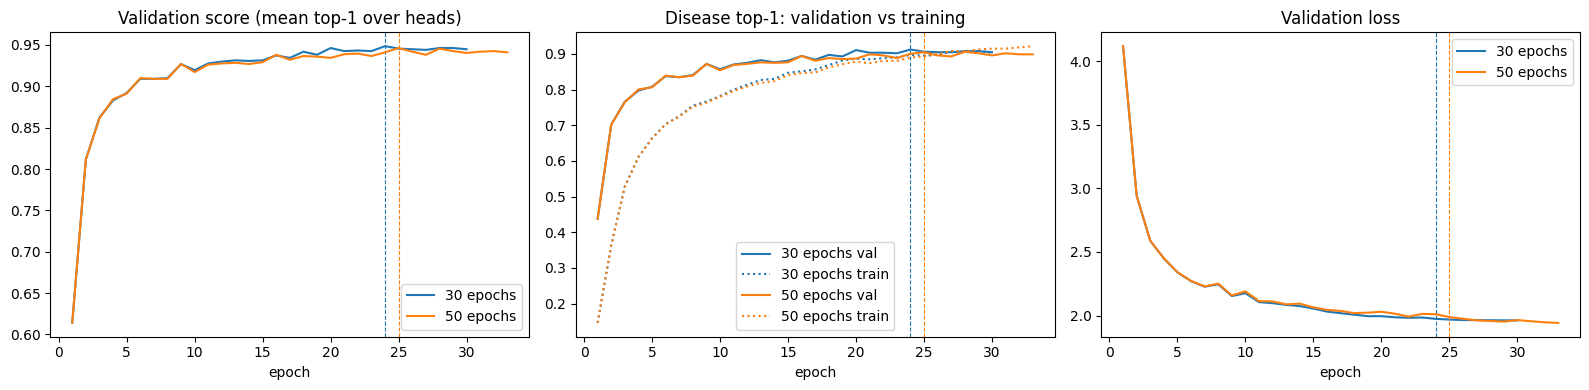

outputs/multitask_dinov2_50ep/eval/calibration_curve.png


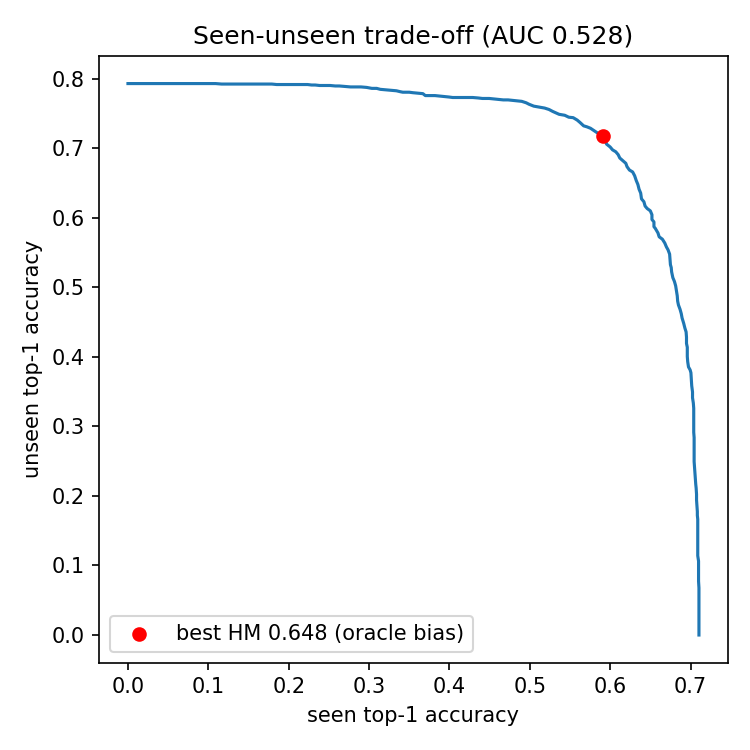

outputs/multitask_dinov2_50ep/eval/top_confusions_seen.png


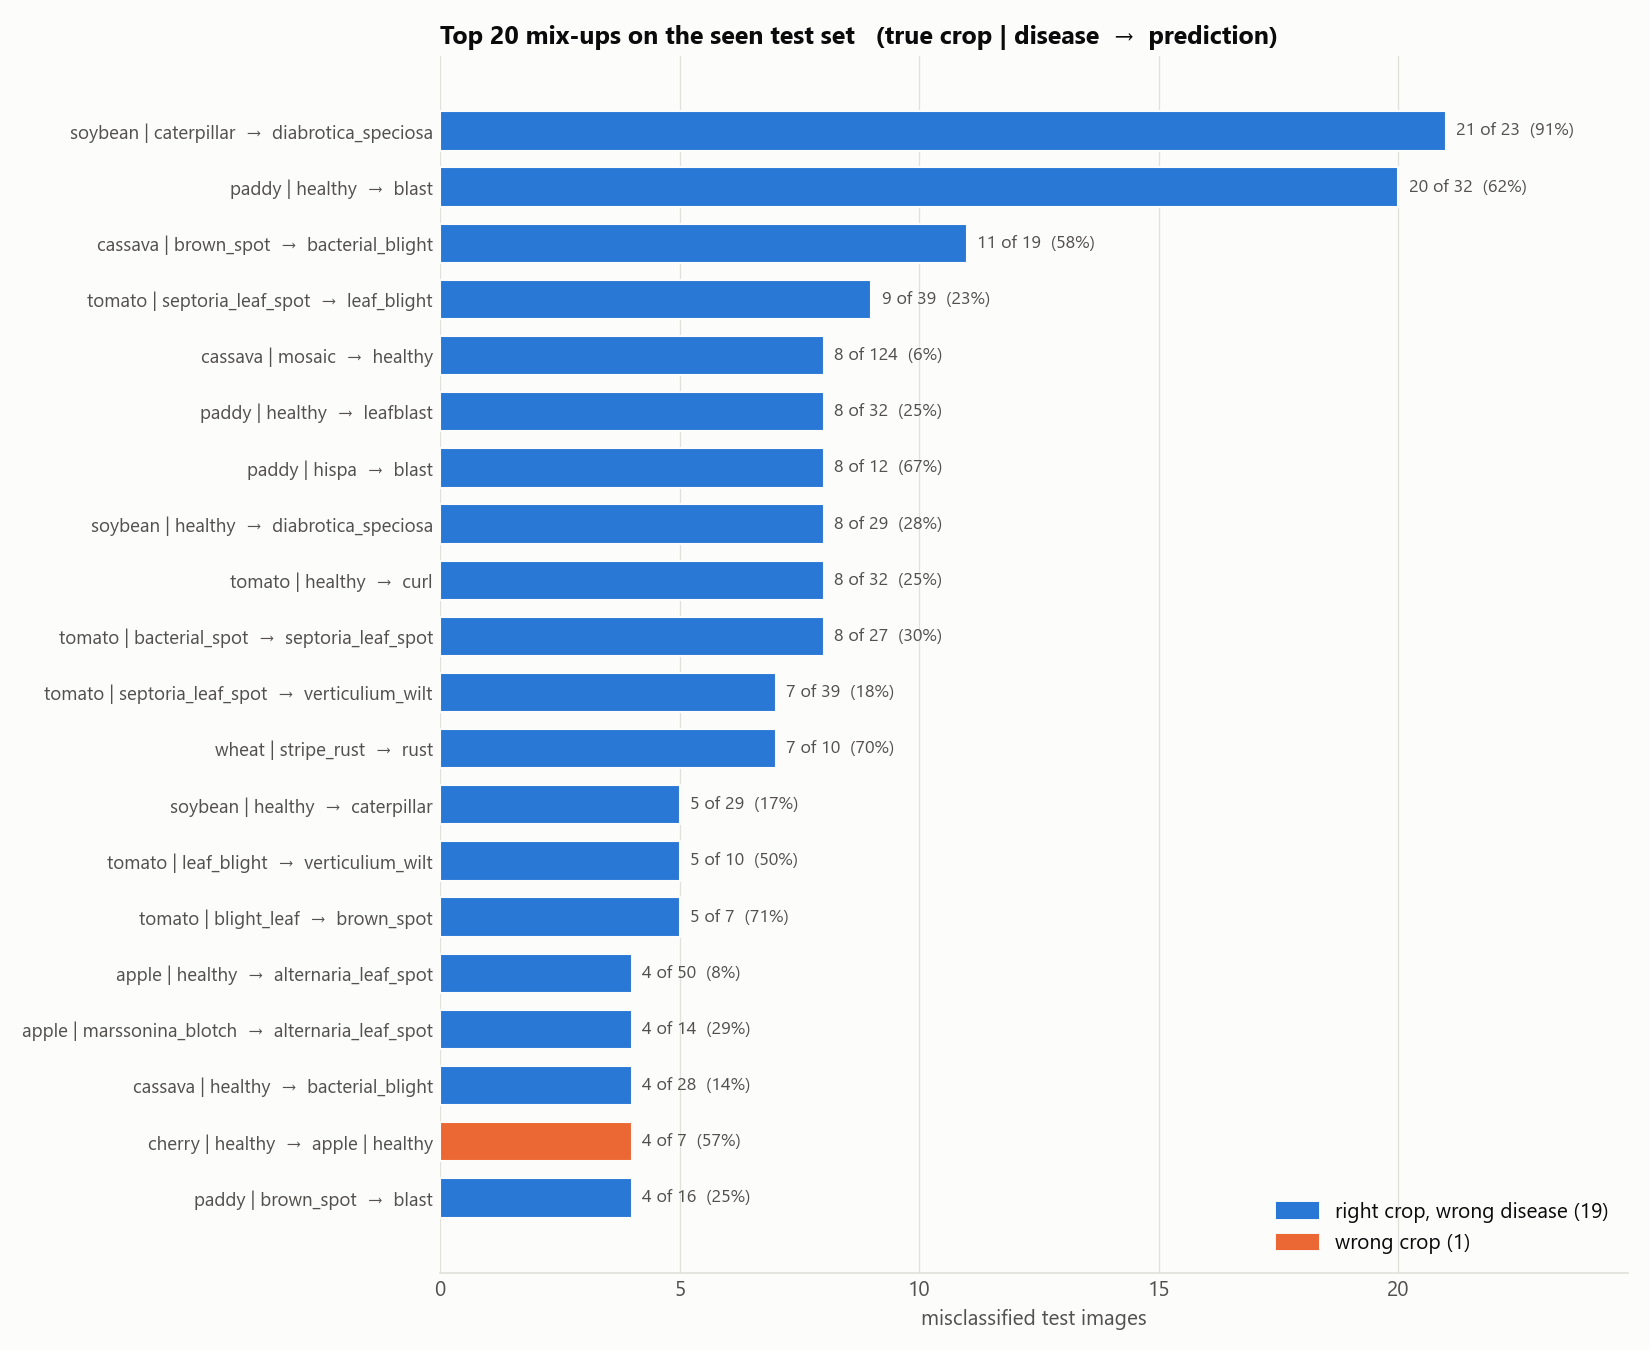

In [7]:
import json

import matplotlib.pyplot as plt
from IPython.display import Image, display

COLS = {
    "seen crop":             lambda m: m["seen"]["crop"]["top1"],
    "seen disease":          lambda m: m["seen"]["disease"]["top1"],
    "seen pair":             lambda m: m["seen"]["composition"]["top1"],
    "unseen crop":           lambda m: m["unseen"]["crop"]["top1"],
    "unseen disease":        lambda m: m["unseen"]["disease"]["top1"],
    "unseen pair":           lambda m: m["unseen"]["composition"]["top1"],
    "unseen pair (closed)":  lambda m: m["unseen"]["composition_closed_world"]["top1"],
    "HM":                    lambda m: m["harmonic_mean"]["top1"],
    "best HM (oracle bias)": lambda m: m["calibrated"]["best_hm"],
    "AUC":                   lambda m: m["calibrated"]["auc"],
}
CAL_COLS = {
    "HM logit-adj (held-out)":   lambda c: c["heldout_cross_fit"]["hm1"],
    "HM-5 logit-adj (held-out)": lambda c: c["heldout_cross_fit"]["hm5"],
    "HM logit-adj (all test)":   lambda c: c["all_test"]["metrics"]["hm1"],
}
labels = {BASELINE: "30 epochs", RUN: "50 epochs"}
# the 30-epoch run uses eval_recal/ (re-evaluated, with logits) when it exists, else its original eval/
eval_dirs = {RUN: RUN_EVAL,
             BASELINE: BASELINE_EVAL if os.path.isfile(f"{BASELINE_EVAL}/metrics.json") else f"outputs/{BASELINE}/eval"}
rows, configs = {}, {}
for exp, label in labels.items():
    path = f"{eval_dirs[exp]}/metrics.json"
    if not os.path.isfile(path):
        continue
    with open(path) as f:
        m = json.load(f)
    rows[label] = {k: fn(m) for k, fn in COLS.items()}
    cal_path = f"{eval_dirs[exp]}/calibration_v2.json"
    if os.path.isfile(cal_path):
        with open(cal_path) as f:
            c = json.load(f)
        rows[label].update({k: fn(c) for k, fn in CAL_COLS.items()})
        configs[label] = c["all_test"]["config"]
if rows:
    table = pd.DataFrame(rows).T
    if len(table) == 2:
        table.loc["change"] = table.loc["50 epochs"] - table.loc["30 epochs"]
    print(f"Top-1 accuracy on the test sets (50-epoch run trained locally on {GPU_NAME})")
    display(table.round(4))
    for label, cfg in configs.items():
        print(f"{label}: logit-adjusted config chosen on all test images: {cfg}")
else:
    print("No evaluation results yet.")

# Training curves of both runs. A dashed line marks the epoch best.pt was taken from.
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for exp, label in labels.items():
    hist = f"outputs/{exp}/history.csv"
    if not os.path.isfile(hist):
        continue
    h = pd.read_csv(hist)
    line, = ax[0].plot(h["epoch"], h["val_score"], label=label)
    ax[1].plot(h["epoch"], h["val_disease_acc"], label=f"{label} val", color=line.get_color())
    ax[1].plot(h["epoch"], h["train_disease_acc"], label=f"{label} train", color=line.get_color(), ls=":")
    ax[2].plot(h["epoch"], h["val_loss"], label=label, color=line.get_color())
    best = int(h.loc[h["val_score"].idxmax(), "epoch"])
    for a in ax:
        a.axvline(best, color=line.get_color(), ls="--", lw=0.8)
ax[0].set(title="Validation score (mean top-1 over heads)", xlabel="epoch")
ax[1].set(title="Disease top-1: validation vs training", xlabel="epoch")
ax[2].set(title="Validation loss", xlabel="epoch")
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()

for png in ["calibration_curve.png", "top_confusions_seen.png"]:
    path = f"outputs/{RUN}/eval/{png}"
    if os.path.isfile(path):
        print(path)
        display(Image(path, width=600))

## 8. Package the results for the team Drive

Collects `outputs/multitask_dinov2_50ep` with `best.pt` (`last.pt` is left out to save space), plus the re-evaluated
30-epoch results in `outputs/multitask_dinov2/eval_recal`. With `SHARE_DIR` set, they are copied there. Otherwise they are
zipped into `outputs/share_dinov2_50ep_local.zip`.

In [8]:
import shutil
import zipfile

files = []
for root, _, fs in os.walk(f"outputs/{RUN}"):
    files += [os.path.join(root, fn) for fn in fs if fn != "last.pt"]
if os.path.isdir(BASELINE_EVAL):   # re-evaluated 30-epoch results (no checkpoint)
    files += [os.path.join(BASELINE_EVAL, fn) for fn in os.listdir(BASELINE_EVAL)]
assert files, "No results yet. Run the training cell first."

if SHARE_DIR:
    for p in files:
        dst = os.path.join(SHARE_DIR, os.path.relpath(p, "outputs"))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(p, dst)
    print(f"Copied {len(files)} files to {SHARE_DIR}")
else:
    zip_path = "outputs/share_dinov2_50ep_local.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            z.write(p, os.path.relpath(p, "outputs"))
    print(f"{len(files)} files -> {os.path.abspath(zip_path)} ({os.path.getsize(zip_path) / 2**20:.0f} MB)")
print("Now save this notebook (Ctrl+S) and upload it too.")

27 files -> c:\COS30082_ML_Project\outputs\share_dinov2_50ep_local.zip (82 MB)
Now save this notebook (Ctrl+S) and upload it too.
